لمجتمع المحلَّل
حللت الطلبات المؤهّلة (المُسلَّمة بتواريخ صالحة) لفحص العلاقات بين المتغيرات الرقمية ومتغير الهدف (is_late). استخدمت معامل ارتباط "سبيرمان" (Spearman correlation) لأنه يقيس قوة واتجاه العلاقة (من -1 إلى 1) ولا يفترض توزيعاً خطياً للبيانات، وهو مناسب هنا لأن كثيراً من المتغيرات ليست خطية (مثل الشهور والساعات).

ماذا يُظهر الرسم (بالأرقام)
النظرة العامة تُظهر أن جميع المتغيرات لها ارتباط ضعيف جداً بـ is_late (القيم تتراوح بين -0.07 و 0.05)، وهذا يعني عدم وجود متغير واحد "سحري" يفسر التأخير بمفرده. أقوى الارتباطات (وإن كانت ضعيفة) هي ارتباط سلبي مع same_state (-0.07)، أي أن الطلبات داخل نفس الولاية أقل عرضة للتأخير. كما توجد ارتباطات سلبية ضعيفة مع approval_month (-0.04) و planned_days (-0.03). أما المتغيرات المرتبطة إيجاباً بالتأخير فهي items_freight_sum و freight_share (0.05 لكل منهما)، يليها purchase_to_approval_hours و items_price_sum (0.02 لكل منهما). أما بقية المتغيرات (مثل عدد المنتجات، عدد البائعين، الوزن، الحجم) فارتباطها بالهدف يقترب من الصفر (0.00 إلى 0.01).

حدود التفسير
ارتباط سبيرمان يقيس "الارتباط" فقط ولا يثبت "السببية" (Association not cause)، فارتفاع سعر الشحن مثلاً قد يرتبط بالتأخير لأنه يعكس مسافات بعيدة وليس لأنه سبب مباشر. كما أن المتغيرات نفسها مترابطة بقوة مع بعضها (Multicollinearity)، مثل ارتباط items_freight_sum مع items_price_sum (0.47) ومع log_weight_g (0.49)، وارتباط freight_share العكسي مع items_price_sum (-0.78). هذا التداخل يعني أن النماذج قد تجد صعوبة في عزل تأثير متغير واحد. وأخيراً، متغير approval_month دوري (حيث ديسمبر=12 ويناير=1)، لذا فإن ارتباطه الرتبي (rank correlation) هو مجرد مؤشر تقريبي.

قائمة قصيرة بالأنماط التي ستحاول النماذج التقاطها (لليوم 7):

البعد الجغرافي: الطلبات داخل نفس الولاية (same_state) أقل تأخيراً، بينما المسافات الطويلة أو الولايات النائية تزيد الاحتمالية.

حساسية الوزن والشحن: الطلبات الثقيلة أو ذات تكلفة شحن مرتفعة (freight) قد تستغرق وقتاً أطول في التجهيز أو النقل.

ضغط الطلبات (Volume): احتمالية تأخر الطلبات في فترات الذروة (مثل نوفمبر ومارس) أو عند شراء عدة منتجات من بائعين مختلفين.

سرعة الموافقة: الوقت المستغرق من الشراء حتى الموافقة (purchase_to_approval_hours) قد يضغط على الجدول الزمني المتبقي للتسليم.

نافذة التسليم القصيرة: الطلبات التي تطلب تسليماً سريعاً (planned_days منخفضة) قد تكون أكثر عرضة للفشل في الالتزام بالوقت.

,pattern,group_a,n_a,rate_a_pct,group_b,n_b,rate_b_pct,difference_pp,intervals_overlap
0,Purchase month (highest vs lowest),2018-03,7003,18.96,2016-10,265,0.75,18.21,False
1,"Customer state (highest vs lowest, n >= 200)",AL,397,21.41,RO,243,2.88,18.53,False
2,Route type,different state,61762,8.05,same state,34631,4.51,3.54,False
3,Planned delivery window (highest vs lowest group),0-10,4651,10.00,41+,3601,2.19,7.80,False
4,Seller structure,multi-seller,1273,1.02,single seller,95120,6.85,-5.83,False
5,Items value (quintiles),Q5 highest,19278,7.49,Q1 lowest,19433,5.90,1.59,False
6,"Product category (highest vs lowest, top 20 by...",baby,2756,8.13,pet_shop,1681,5.06,3.07,False
7,Number of items,1 item,86766,6.94,4+ items,937,5.23,1.71,True


,period,route_group,n,late,rate,ci_low,ci_high,small_sample
0,other months,different state,48076,2348,0.0488,0.0469,0.0508,False
1,other months,same state,27471,1025,0.0373,0.0351,0.0396,False
2,"peak months (2017-11, 2018-02, 2018-03)",different state,13686,2622,0.1916,0.1851,0.1983,False
3,"peak months (2017-11, 2018-02, 2018-03)",same state,7160,536,0.0749,0.0690,0.0812,False


,seller_group,count,mean,std,min,25%,50%,75%,max
0,multi-seller,1273.0,25.54,8.16,2.0,21.0,25.0,30.0,80.0
1,single seller,95120.0,23.85,8.77,1.0,18.0,23.0,29.0,154.0


,route_group,count,mean,std,min,25%,50%,75%,max
0,different state,61762.0,27.30,7.68,1.0,22.0,26.0,31.0,154.0
1,same state,34631.0,17.74,7.07,1.0,13.0,17.0,21.0,150.0


,feature,spearman_with_is_late
0,same_state,-0.0676
1,items_freight_sum,0.0523
2,approval_month,-0.0389
3,purchase_to_approval_hours,0.0315
4,n_sellers,-0.0265
5,is_multi_seller,-0.0265
6,planned_days,-0.0253
7,items_price_sum,0.0240
8,n_items,-0.0199
9,log_weight_g,0.0164


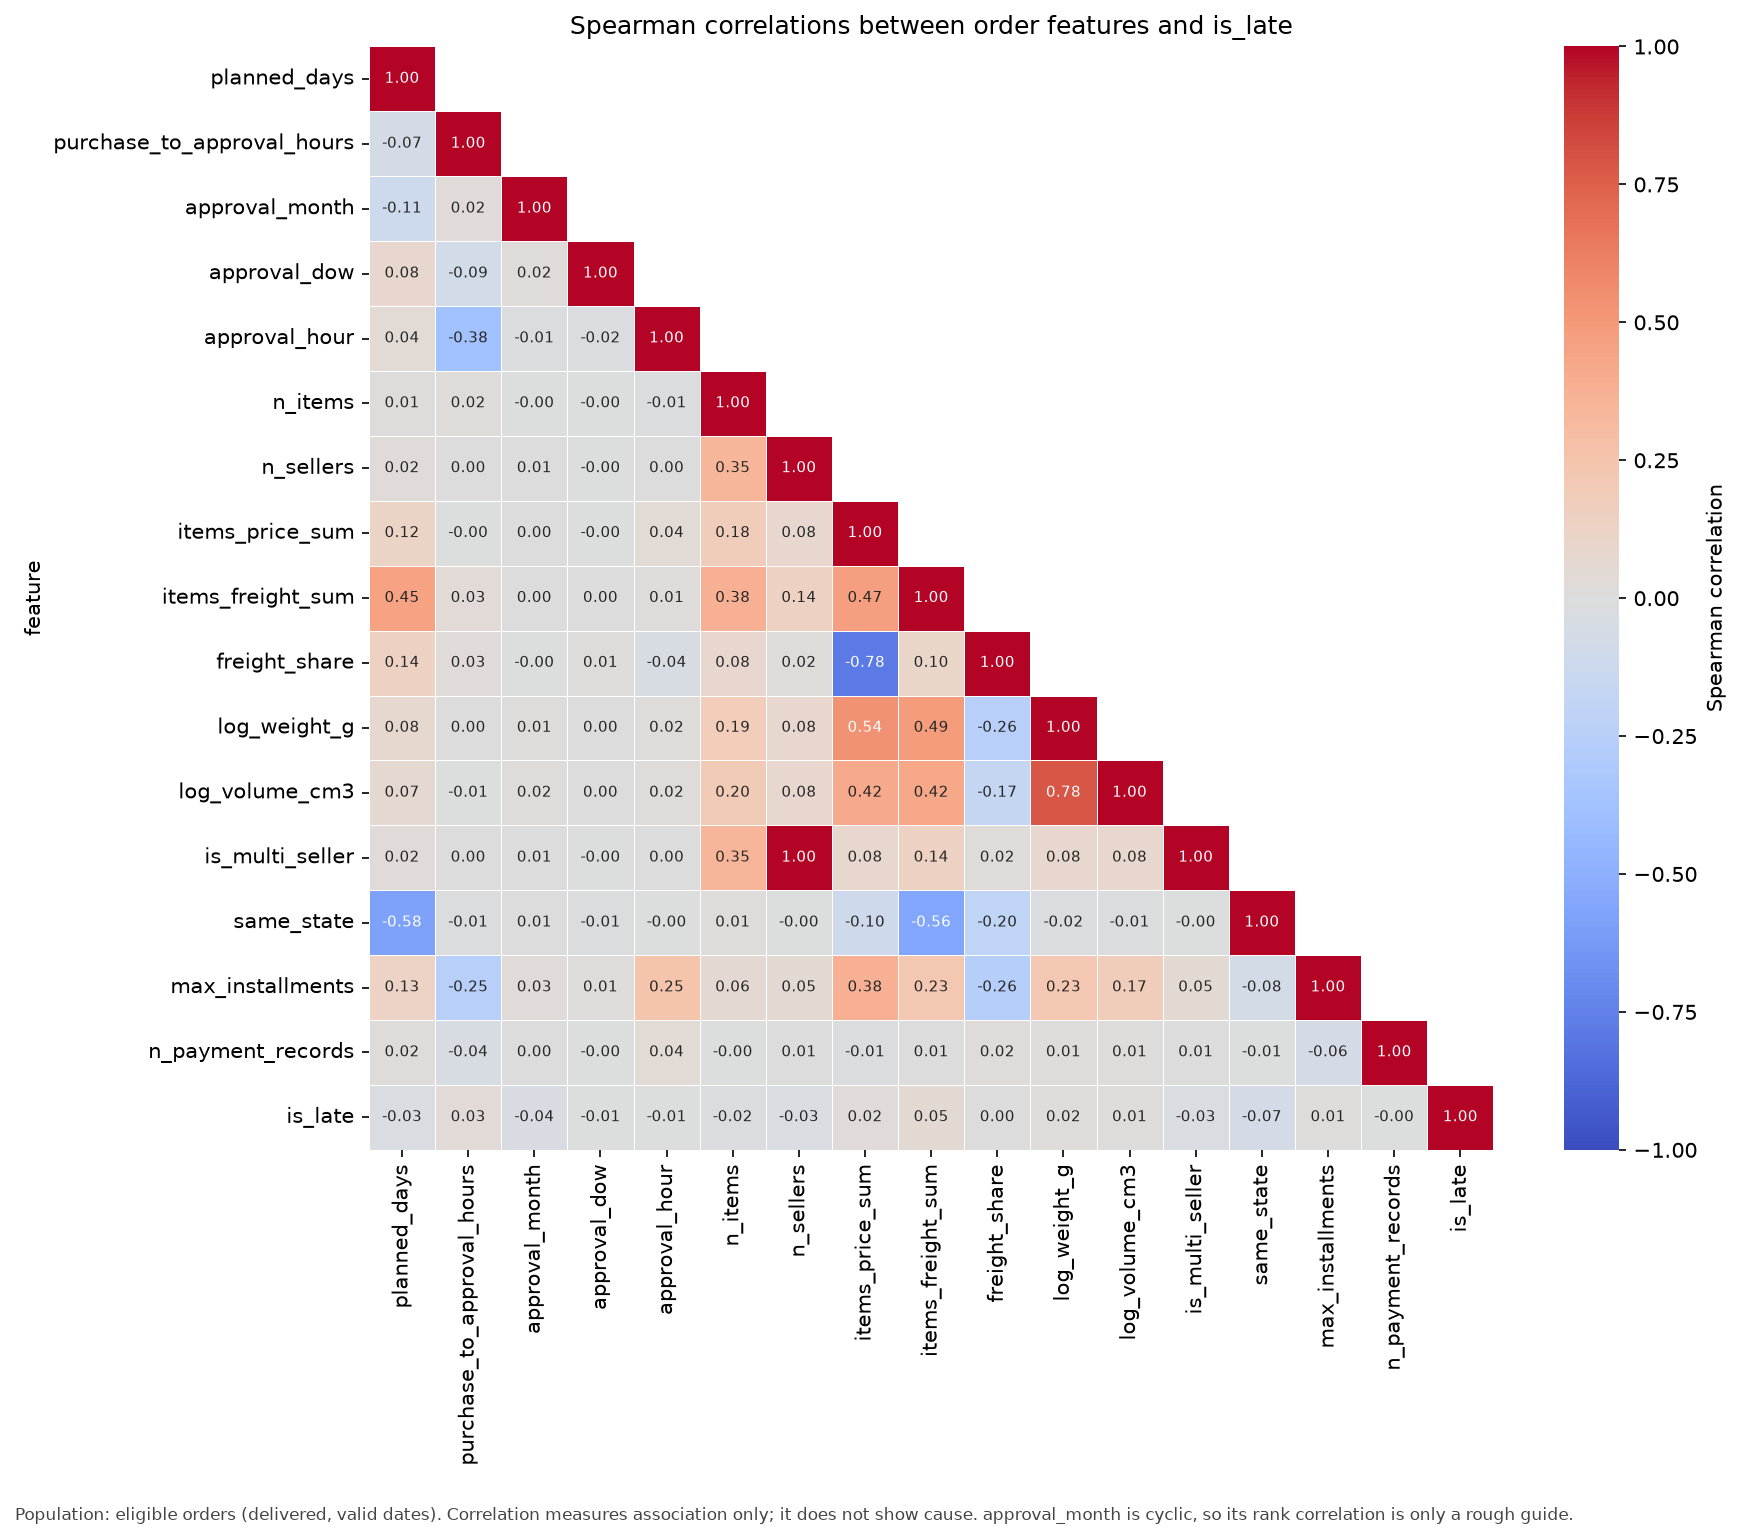

In [5]:
display(t2["pattern_summary"])
display(t2["late_by_period_x_route"].round(4))
display(t2["planned_days_by_seller_group"])
display(t2["planned_days_by_route_group"])
display(t2["correlation_with_target"])
display(Image(filename=str(paths["fig11_correlation_heatmap.png"])))

لأنماط التي تستحق المتابعة


المجتمع المحلَّل
حللت إجمالي الطلبات كافة (99,441 طلباً) لأفهم أسباب استبعاد بعضها من التحليل، لأن حساب نسبة التأخير يتطلب طلبات "مؤهّلة" (أي مسلّمة ولديها تواريخ صالحة). الرسم يوضح أسباب الاستبعاد وحجم الطلبات المستبعدة شهرياً.

ماذا يُظهر الرسم (بالأرقام)
الرسم الأيسر (بمقياس لوغاريتمي) يبيّن أن السبب الأكبر للاستبعاد هو عدم وجود حالة "تم التسليم" (not_delivered_status) وعددها 2,963 طلباً، يليه وجود تاريخ موافقة بعد التسليم (approval_after_delivery) بـ 61 طلباً، ثم نقص تاريخ الموافقة (missing_approval_date) بـ 14 طلباً. الأسباب الأخرى نادرة جداً (8 و1 و1). أما الرسم الأيمن فيوضح أن نسبة الاستبعاد كانت مرتفعة جداً في بداية البيانات (شهر 2016-10 بنسبة 18.2%، و2017-01 بنسبة 7.9%)، ثم استقرت لاحقاً بين 1% و3% في معظم شهور 2017 و2018.

حدود التفسير
لا أعتمد على نسب الاستبعاد في الشهور الأولى (مثل 2016-10) لأن عدد الطلبات فيها أقل من 200، وبالتالي النسبة قد تكون مضللة أو غير مستقرة. أيضاً، الارتفاع الواضح في نسبة الاستبعاد في بداية المشروع يعطي إشارة إلى وجود مشاكل في تسجيل البيانات أو اكتمالها في تلك الفترة، مما يبرر التركيز على الفترات اللاحقة أو التعامل بحذر مع بيانات 2016. وأخيراً، استبعاد هذه الطلبات لا يعني إهمالها، بل يجب الانتباه إلى أن النتائج تمثل فقط الطلبات التي اكتملت بياناتها.

,reason,n_orders,pct_of_all_orders
0,not_delivered_status,2963,2.980
1,approval_after_delivery,61,0.061
2,missing_approval_date,14,0.014
3,delivered_without_customer_date,8,0.008
4,no_payment_record,1,0.001
5,estimated_before_approval,1,0.001


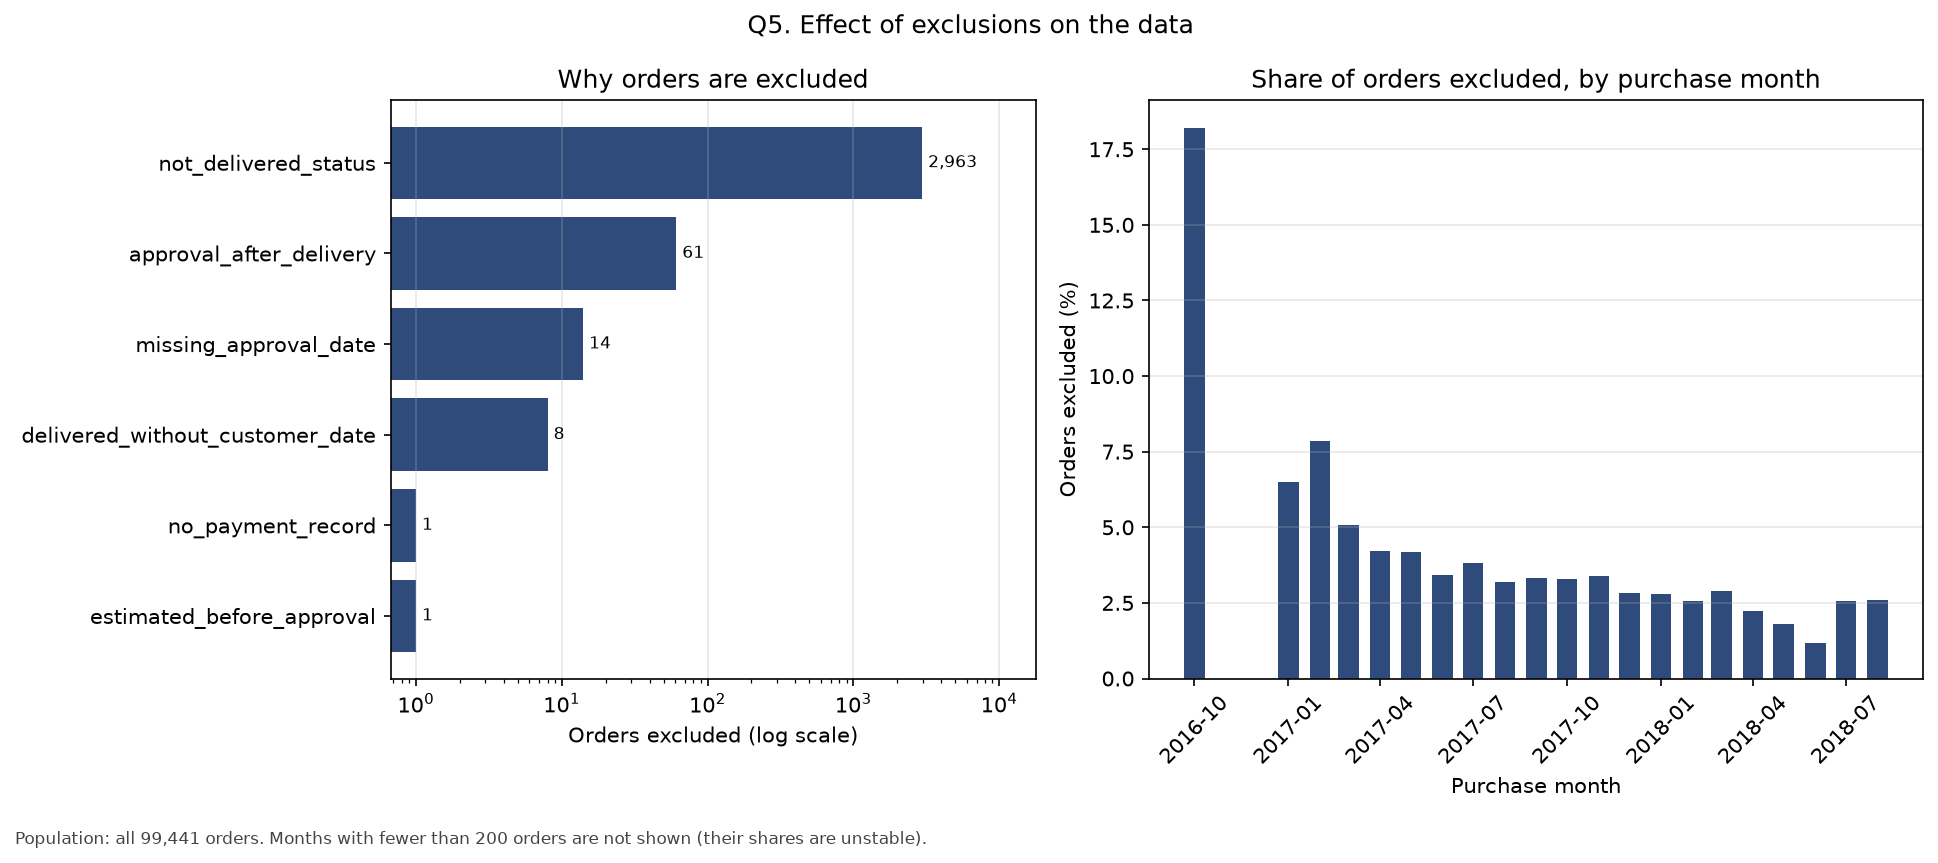

,measure,all_orders,eligible_orders,difference
0,orders,99441.000,96393.000,-3048.000
1,share of customers in SP (%),41.981,41.947,-0.034
2,multi-seller share among orders with items (%),1.295,1.321,0.025
3,same-state share among orders with items (%),35.948,35.927,-0.021
4,median items price sum,86.900,86.600,-0.300
5,median planned days,23.000,23.000,0.000
6,mean number of items,1.142,1.142,0.000


,customer_state,n_all,n_eligible,pct_excluded,share_all_pct,share_eligible_pct,share_diff_pp
0,RR,46,41,10.870,0.046,0.043,-0.004
1,CE,1336,1277,4.416,1.344,1.325,-0.019
2,SE,350,335,4.286,0.352,0.348,-0.004
3,MA,747,716,4.150,0.751,0.743,-0.008
4,RO,253,243,3.953,0.254,0.252,-0.002
5,RJ,12852,12346,3.937,12.924,12.808,-0.116
6,AL,413,397,3.874,0.415,0.412,-0.003
7,PI,495,476,3.838,0.498,0.494,-0.004
8,BA,3380,3256,3.669,3.399,3.378,-0.021
9,PE,1652,1593,3.571,1.661,1.653,-0.009


,feature,n_missing,pct_missing,late_rate_when_missing_pct,late_rate_when_observed_pct
0,log_weight_g,22,0.023,0.00,6.78
1,log_volume_cm3,16,0.017,0.00,6.78
2,primary_category == 'unknown',1357,1.408,7.15,6.77


In [4]:
display(t2["exclusion_reasons"])
display(Image(filename=str(paths["fig12_exclusion_impact.png"])))
display(t2["representation_summary"])
display(t2["representation_by_state"].head(10))
display(t2["missingness_vs_target"])

أثر المفقود والاستبعاد


المجتمع المحلَّل
حللت الطلبات المؤهّلة (المُسلَّمة بتواريخ صالحة)، وقسمتها إلى فئتين: الطلبات التي وصلت في وقتها (on time) وعددها 89,862، والطلبات المتأخرة (late) وعددها 6,531. المقياس الأساسي هنا هو "نافذة التسليم المخططة" (Planned delivery window) أي عدد الأيام من الموافقة على الطلب حتى التاريخ المتوقع للتسليم، بالإضافة إلى عدد الساعات من الشراء حتى الموافقة.

ماذا تُظهر الرسوم (بالأرقام)
الرسم الأول (الهستوغرام) يبيّن أن توزيع النافذة المخططة متشابه جداً بين الفئتين، حيث يتركز معظم الطلبات بين 20 و30 يوماً. الرسم الثاني (الصندوقي) يؤكد ذلك: الوسيط (Median) لنافذة التسليم هو 23.0 يوماً لكل من الطلبات المتأخرة وغير المتأخرة. أما بالنسبة لوقت الموافقة، فالوسيط متقارب جداً (0.3 ساعة للطلبات في وقتها مقابل 0.4 ساعة للمتأخرة)، لكن المدى الربيعي للطلبات المتأخرة أعلى بكثير (يمتد حتى حوالي 19 ساعة) مقارنة بالطلبات في وقتها (تمتد حتى 14 ساعة). الرسم الثالث (النقاطي) يوضح أن نسبة التأخير تكون مرتفعة جداً (تصل إلى 21% و34%) عندما تكون نافذة التسليم قصيرة جداً (أقل من 10 أيام). بعد ذلك، تستقر النسبة حول المتوسط العام (6.8%، الخط الأحمر) لمعظم النوافذ بين 15 و40 يوماً، ثم تنخفض تدريجياً في النوافذ الطويلة (أكثر من 40 يوماً).

حدود التفسير
الرسم الثالث يحذرنا من قراءة النتائج بشكل مطلق؛ النقاط الرمادية (مثل النافذة الأقل من 5 أيام أو الأكثر من 45 يوماً) تمثل أياماً تحتوي على أقل من 200 طلب، وبالتالي نسب التأخير فيها غير موثوقة إحصائياً (ضجيج). أيضاً، الرسم النقاطي لا يُظهر الأيام التي تحتوي على أقل من 30 طلباً. وأخيراً، تشابه الوسيط (23 يوماً) بين الفئتين لا يعني أن النافذة المخططة لا تؤثر؛ بل يعني أننا بحاجة لدراسة عوامل أخرى (مثل المسافة، أو ولاية العميل، أو نوع الشحن) لفهم سبب تأخر بعض الطلبات رغم تساوي النوافذ المخططة.

,planned_group,n,late,rate,ci_low,ci_high,small_sample
0,0-10,4651,465,0.1000,0.0917,0.1089,False
1,11-15,10814,483,0.0447,0.0409,0.0487,False
2,16-20,17645,1335,0.0757,0.0718,0.0797,False
3,21-25,26081,2049,0.0786,0.0754,0.0819,False
4,26-30,18786,1307,0.0696,0.0660,0.0733,False
5,31-40,14815,813,0.0549,0.0513,0.0587,False
6,41+,3601,79,0.0219,0.0176,0.0273,False


,is_late,count,mean,std,min,25%,50%,75%,max
0,0,89862.0,23.95,8.84,1.0,18.0,23.0,29.0,154.0
1,1,6531.0,22.69,7.64,1.0,19.0,23.0,27.0,69.0


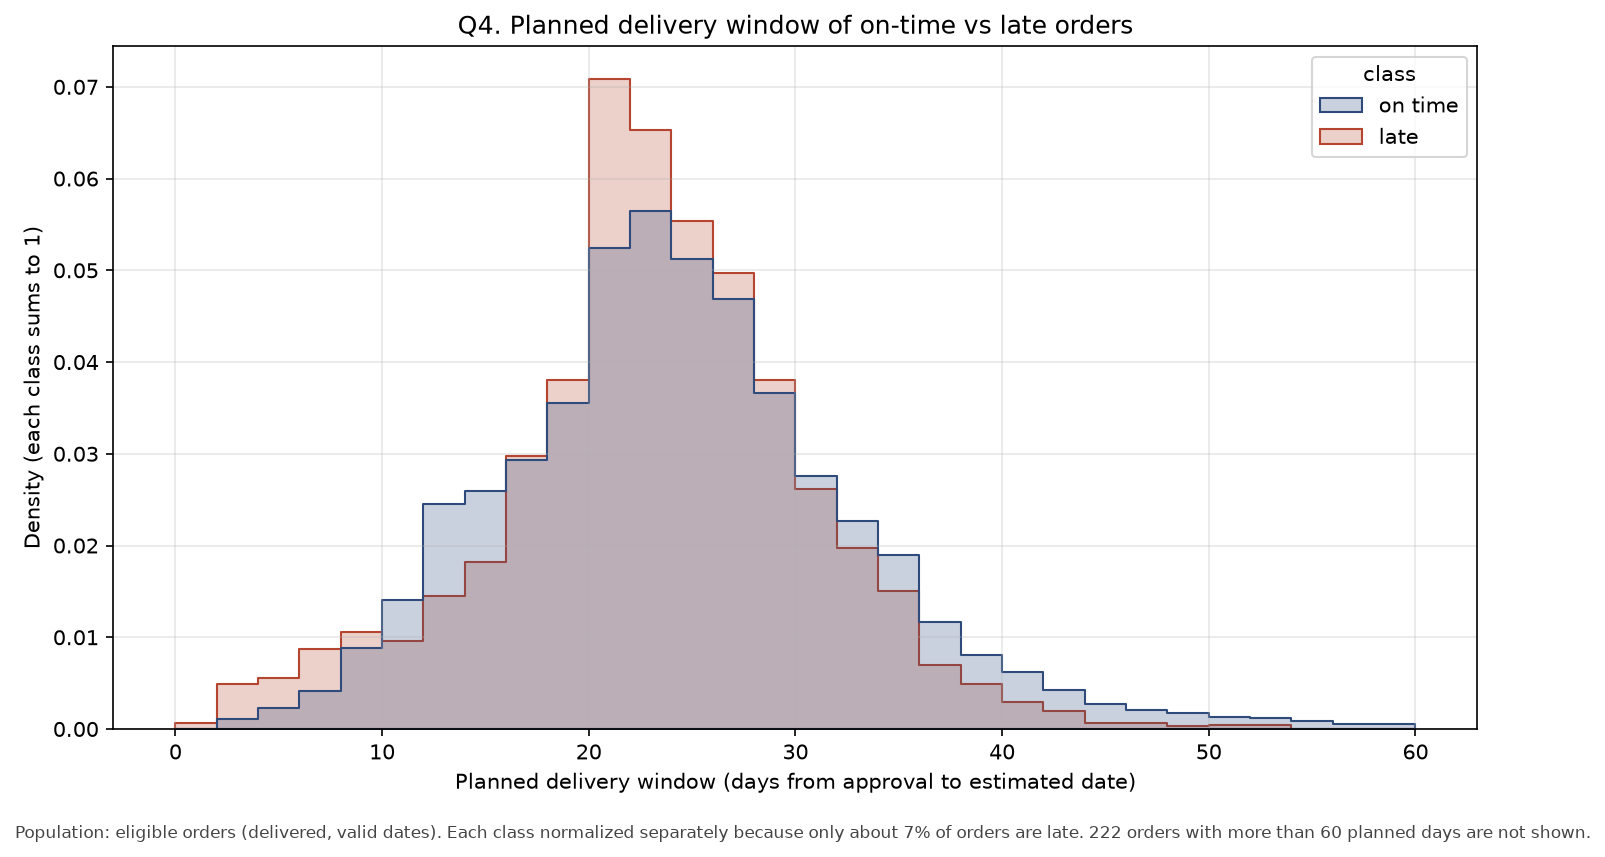

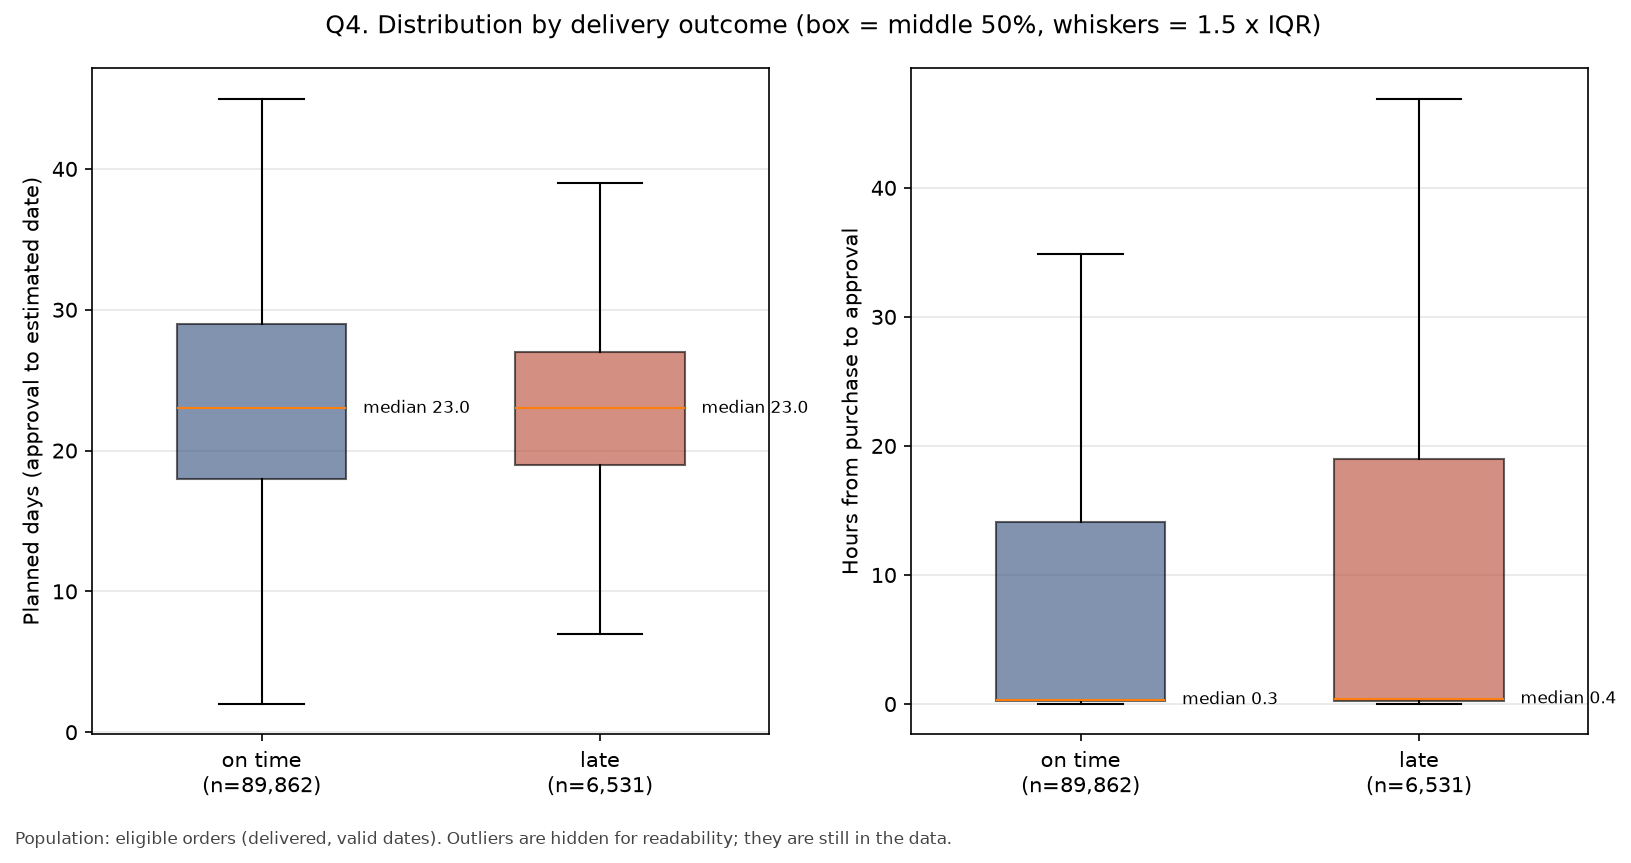

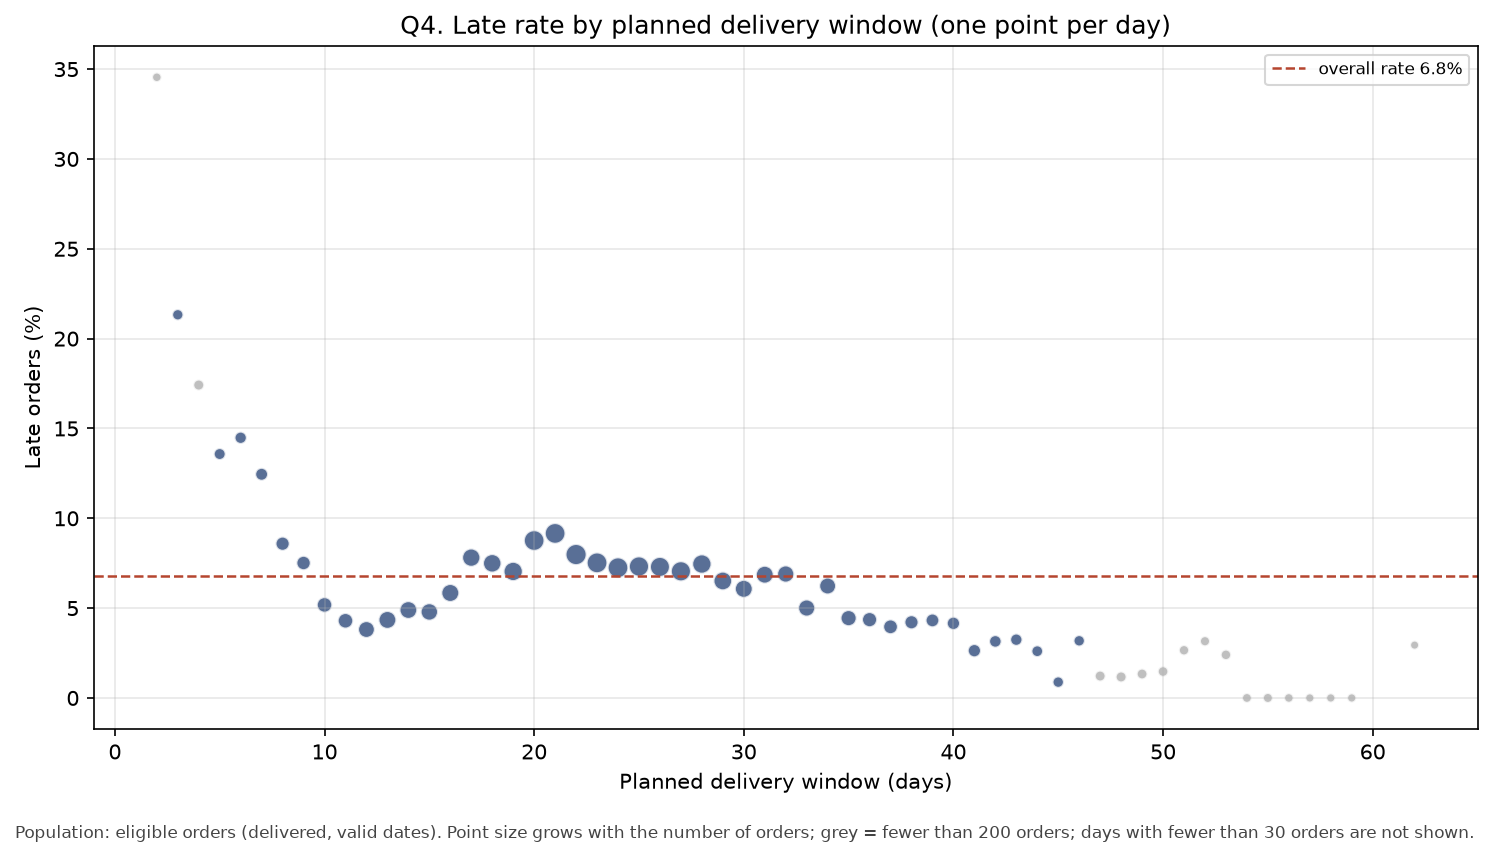

,planned_group,route_group,n,late,rate,ci_low,ci_high,small_sample
0,0-10,different state,359,38,0.1058,0.0781,0.1420,False
1,0-10,same state,4292,427,0.0995,0.0909,0.1088,False
2,11-15,different state,1552,107,0.0689,0.0574,0.0826,False
3,11-15,same state,9262,376,0.0406,0.0368,0.0448,False
4,16-20,different state,6532,816,0.1249,0.1171,0.1332,False
5,16-20,same state,11113,519,0.0467,0.0429,0.0508,False
6,21-25,different state,19718,1880,0.0953,0.0913,0.0995,False
7,21-25,same state,6363,169,0.0266,0.0229,0.0308,False
8,26-30,different state,16581,1256,0.0757,0.0718,0.0799,False
9,26-30,same state,2205,51,0.0231,0.0176,0.0303,False


In [3]:
display(t2["late_by_planned_group"].round(4))
display(t2["planned_days_by_class"])
display(Image(filename=str(paths["fig08_planned_days_histogram.png"])))
display(Image(filename=str(paths["fig09_boxplots_by_outcome.png"])))
display(Image(filename=str(paths["fig10_planned_days_scatter.png"])))
display(t2["late_by_planned_x_route"].round(4))

المدة المخططة والتأخر


توزيع الفئات (النسبة):
يبيّن الرسم الأيسر وجود خلل واضح في توزيع الفئات (Class Imbalance). من إجمالي الطلبات المؤهّلة، هناك 89,862 طلباً وصل في وقته (on time) وبنسبة 93.2%، بينما تأخر 6,531 طلباً فقط (late) وبنسبة 6.8%. أي أن الفئة السلبية (عدم التأخير) تمثل الأغلبية الساحقة من البيانات.

لماذا الدقة 93% بلا قيمة:
الرسم الأيمن يوضح نموذجاً "غبياً" (Baseline) يخمّن دائماً أن الطلب سيصل في وقته (on time) ولا يتأخر أبداً. هذا النموذج حقق دقة (Accuracy) تبلغ 93.2%، وهذا رقم يبدو ممتازاً ولكنه مضلل تماماً؛ لأن النموذج لم يتعلم شيئاً، بل استفاد فقط من كون الأغلبية الساحقة من الطلبات غير متأخرة. الدليل على فشله هو أن نسبة الاستدعاء (Recall) لفئة التأخير تساوي 0.0%، أي أنه فشل في اكتشاف أي طلب متأخر واحد. لذلك، في البيانات غير المتوازنة، الدقة العالية قد تخفي نموذجاً عديم الفائدة تماماً.

المقاييس البديلة:
لهذا السبب لا نعتمد على الدقة وحدها، بل نستخدم مقاييس تركز على الفئة المهمة (التأخير):

الإحكام (Precision): من بين الطلبات التي توقع النموذج أنها ستتأخر، كم عددها تأخر فعلاً؟ (قياس دقة التوقع الإيجابي).

الاستدعاء (Recall): من بين كل الطلبات التي تأخرت فعلاً في الواقع، كم عدداً استطاع النموذج اكتشافه؟ (قياس قدرة النموذج على اصطياد التأخيرات).

F1-Score: المتوسط التوازني بين الإحكام والاستدعاء، ويعطينا رقماً واحداً يعكس أداء النموذج على فئة التأخير.

Average Precision (AP): مقياس شامل يلخص منحنى الدقة والاستدعاء (Precision-Recall Curve)، وهو ممتاز جداً في حالات عدم توازن الفئات لأنه يعطي صورة أوضح عن قدرة النموذج الحقيقية بعيداً عن تضليل الدقة العامة.

,measure,value
0,eligible orders,96393.000
1,on time (is_late = 0),89862.000
2,late (is_late = 1),6531.000
3,late share (%),6.775
4,imbalance ratio (on time : late),13.760
5,accuracy of always predicting 'on time' (%),93.225
6,recall for the late class of that rule (%),0.000


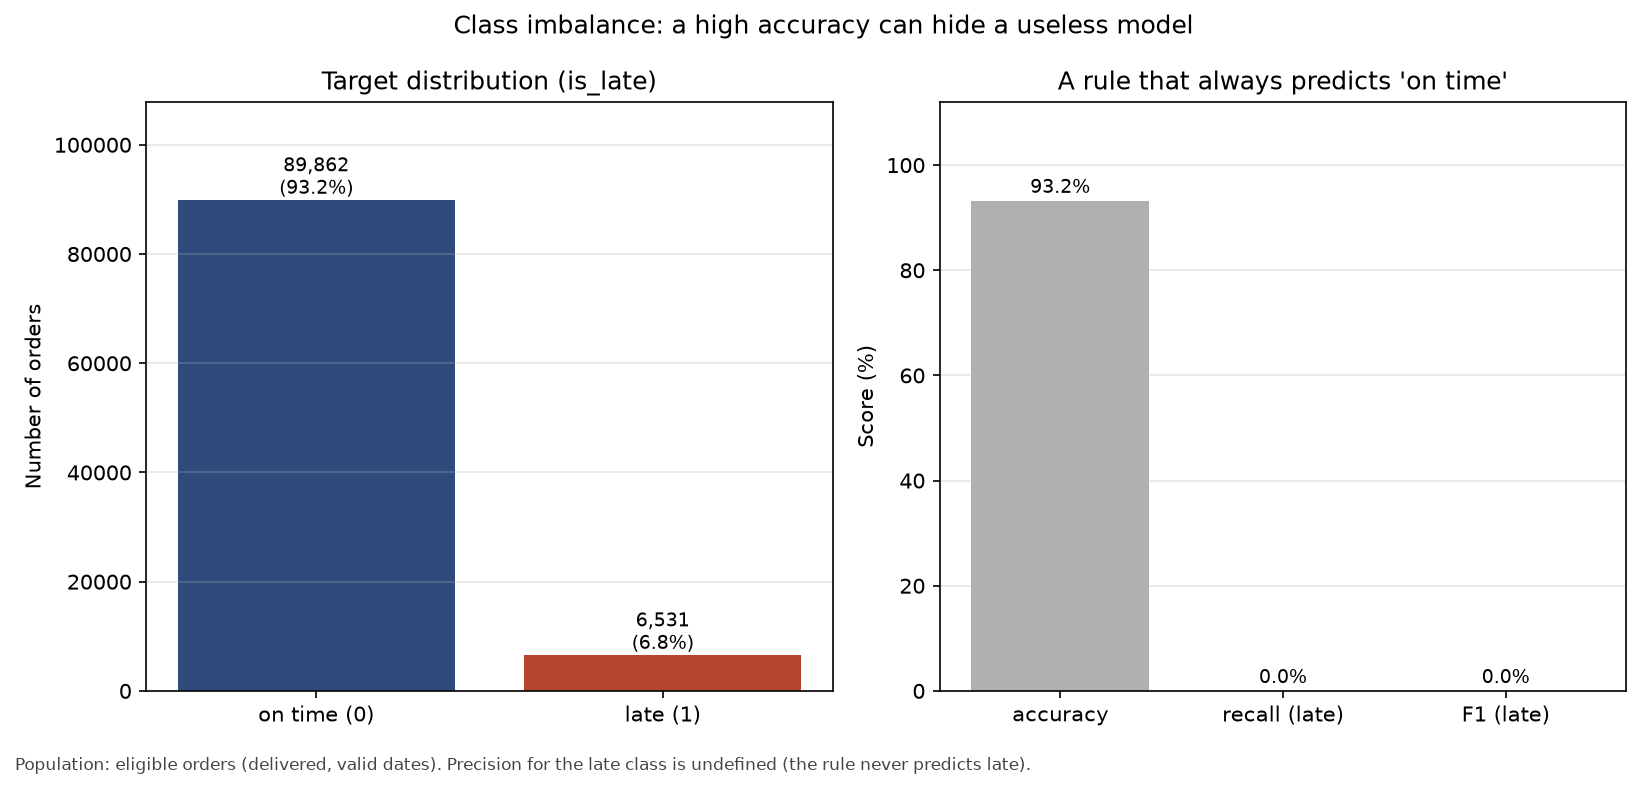

In [2]:
display(t2["target_balance"])
display(Image(filename=str(paths["fig07_target_distribution.png"])))

توزيع الهدف وعدم التوازن

In [1]:
import sys
sys.path.append("..")

import pandas as pd
from IPython.display import Image, display

from src import config
from src.eda import load_full_table, prepare
from src.eda_part2 import add_planned_columns, build_part2_tables, make_part2_figures

pd.set_option("display.width", 200)
full = load_full_table()
el, tables = prepare(full)
el = add_planned_columns(el)
t2 = build_part2_tables(full, el, tables)
paths = {p.name: p for p in make_part2_figures(full, el, tables, t2, config.FIGURES_DIR)}
print(f"All orders: {len(full):,} | eligible: {len(el):,}")

All orders: 99,441 | eligible: 96,393
